# 01. Разведочный анализ данных TCGA

**Цель ноутбука:** посмотреть на данные до обучения моделей. Сколько у нас опухолей каждого типа, разделяются ли типы рака сами по себе и нет ли в данных ловушек, на которые модель может «купиться».

**Данные:** TCGA Pan-Cancer Atlas — RNA-seq первичных опухолей, по одному образцу на пациента. Подготовка сделана скриптом `src/prepare.py`:
- значения экспрессии уже в шкале log2(нормированный счёт + 1);
- пациенты разделены на обучающую (70%), валидационную (15%) и тестовую (15%) выборки с сохранением доли каждого типа рака;
- гены отфильтрованы **только по обучающей выборке**, чтобы тестовые данные никак не влияли на подготовку.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
FIG = ROOT / 'results' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42

# dtype=str: один из кодов центров сбора TCGA буквально "NA", pandas иначе прочитал бы его как пропуск.
samples = pd.read_csv(ROOT / 'data' / 'processed' / 'samples.csv', dtype=str, keep_default_na=False)
expr = pd.read_pickle(ROOT / 'data' / 'processed' / 'expression.pkl')

primary = samples[samples['split'] != 'metastasis'].reset_index(drop=True)
print(f'Первичных опухолей: {len(primary)}, типов рака: {primary.cancer_type.nunique()}')
print(f'Генов после фильтрации: {expr.shape[1]}')
print(f'Метастазов отложено для отдельной проверки: {(samples.split == "metastasis").sum()}')
primary.head()

Первичных опухолей: 9676, типов рака: 32
Генов после фильтрации: 17456
Метастазов отложено для отдельной проверки: 394


,sample,patient,site,sample_type,cancer_type,split
0,TCGA-02-0047-01,TCGA-02-0047,02,01,GBM,train
1,TCGA-02-0055-01,TCGA-02-0055,02,01,GBM,train
2,TCGA-02-2483-01,TCGA-02-2483,02,01,GBM,test
3,TCGA-02-2485-01,TCGA-02-2485,02,01,GBM,train
4,TCGA-02-2486-01,TCGA-02-2486,02,01,GBM,test


## 1. Сколько опухолей каждого типа

Типы рака в TCGA представлены очень неравномерно. Это важно: если модель будет просто чаще угадывать большие классы, обычная точность (accuracy) будет выглядеть хорошо, а маленькие классы она будет путать. Поэтому позже мы будем смотреть на **macro-F1**, где каждый тип рака весит одинаково.

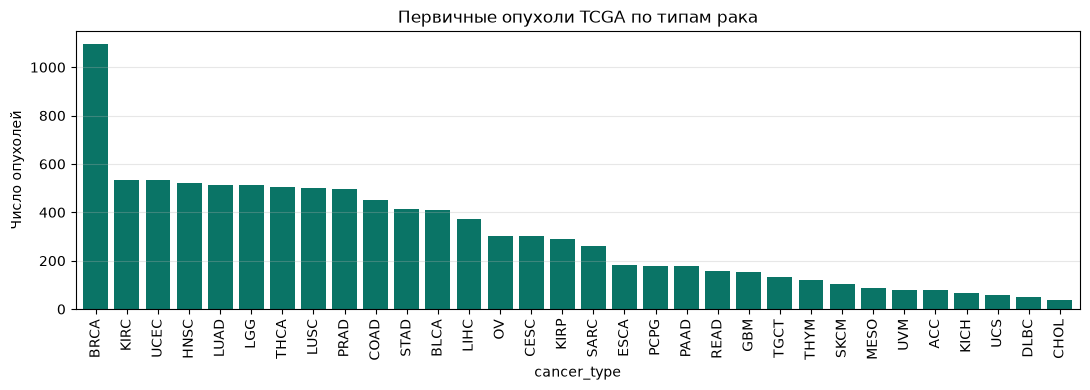

Самый большой класс: BRCA (1095), самый маленький: CHOL (36)
Разница в 30 раз


In [2]:
counts = primary['cancer_type'].value_counts()
fig, ax = plt.subplots(figsize=(11, 4))
counts.plot.bar(ax=ax, color='#0a7466', width=0.8)
ax.set_ylabel('Число опухолей')
ax.set_title('Первичные опухоли TCGA по типам рака')
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / 'class_balance.png', dpi=150)
plt.show()
print(f'Самый большой класс: {counts.index[0]} ({counts.iloc[0]}), самый маленький: {counts.index[-1]} ({counts.iloc[-1]})')
print(f'Разница в {counts.iloc[0] / counts.iloc[-1]:.0f} раз')

Проверим разбиение: доля каждого типа рака должна быть примерно одинаковой во всех трёх выборках, а самые маленькие классы должны попасть и в тест.

In [3]:
split_table = pd.crosstab(primary['cancer_type'], primary['split'])[['train', 'val', 'test']]
split_table.loc['Всего'] = split_table.sum()
split_table.sort_values('train', ascending=False)

split,train,val,test
cancer_type,,,
Всего,6772,1452,1452
BRCA,767,164,164
KIRC,373,80,80
UCEC,372,80,80
HNSC,364,78,78
LGG,361,77,77
LUAD,361,77,77
THCA,353,76,76
LUSC,351,75,75


## 2. Разделяются ли типы рака сами по себе (UMAP)

У каждой опухоли ~15 тысяч чисел (по одному на ген). Чтобы увидеть их на плоскости, сжимаем данные:
1. берём 2000 генов с самой большой изменчивостью **в обучающей выборке**;
2. приводим каждый ген к одному масштабу (стандартизация);
3. PCA сжимает 2000 генов до 50 главных компонент;
4. UMAP раскладывает эти 50 компонент на плоскости так, чтобы похожие опухоли оказались рядом.

Если точки одного цвета собираются в отдельные облака, значит, у типов рака есть собственный «экспрессионный почерк» и классификатор, скорее всего, справится.

In [4]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import umap

train = primary[primary['split'] == 'train']
X_train = expr.loc[train['sample']]
# У ~1 100 генов есть редкие пропуски (<1% опухолей): заполняем медианой обучающей выборки.
train_median = X_train.median()
X_train = X_train.fillna(train_median)
top_genes = X_train.var().sort_values(ascending=False).index[:2000]

Z = StandardScaler().fit_transform(X_train[top_genes])
pcs = PCA(n_components=50, random_state=SEED).fit_transform(Z)
emb = umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=SEED).fit_transform(pcs)
train = train.assign(umap1=emb[:, 0], umap2=emb[:, 1])
print('UMAP построен для', len(train), 'опухолей обучающей выборки')

C:\Users\Asus\.venvs\oncotype-expr\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\Asus\.venvs\oncotype-expr\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP построен для 6772 опухолей обучающей выборки


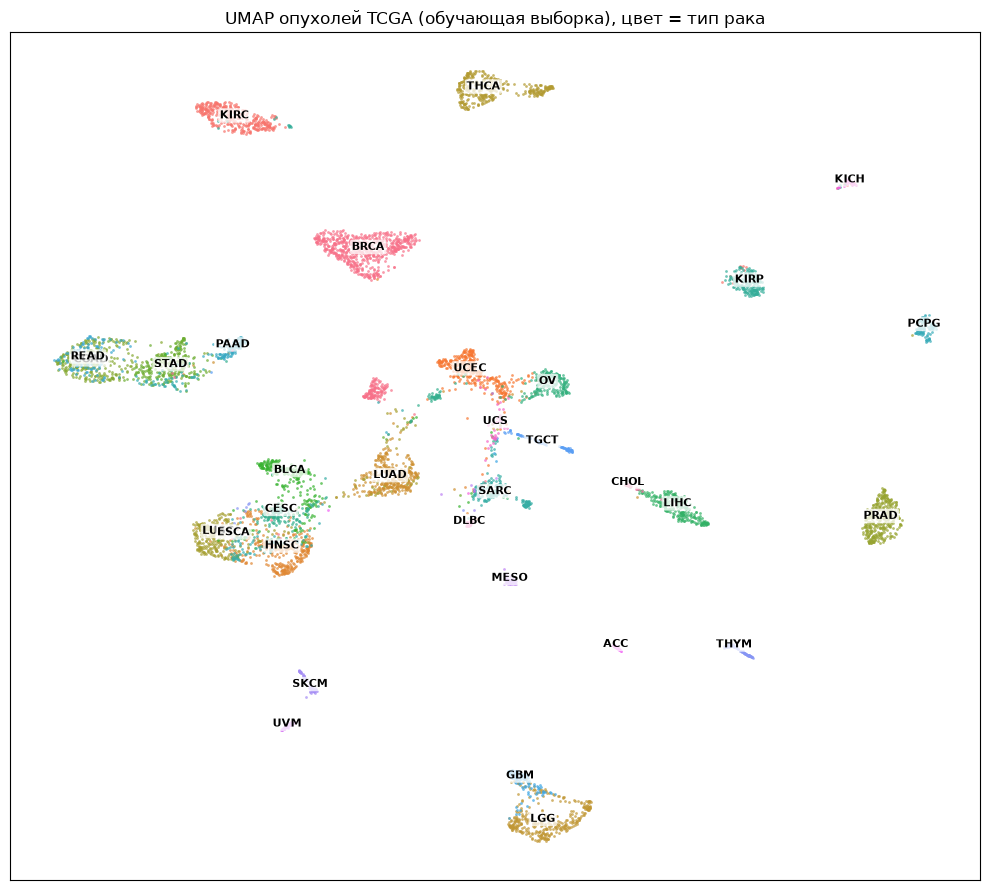

In [5]:
types = counts.index.tolist()
palette = dict(zip(types, sns.color_palette('husl', len(types))))
fig, ax = plt.subplots(figsize=(10, 9))
for t in types:
    d = train[train.cancer_type == t]
    ax.scatter(d.umap1, d.umap2, s=4, color=palette[t], alpha=0.7, linewidths=0)
    ax.annotate(t, (d.umap1.median(), d.umap2.median()), fontsize=8, weight='bold', ha='center',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.75))
ax.set_title('UMAP опухолей TCGA (обучающая выборка), цвет = тип рака')
ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
fig.savefig(FIG / 'umap_cancer_types.png', dpi=150)
plt.show()

Насколько хорошо разделяются типы, можно оценить числом: для каждой опухоли посмотрим на 15 ближайших соседей в пространстве PCA и посчитаем, какая доля из них того же типа рака.

In [6]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=16).fit(pcs)
_, idx = nn.kneighbors(pcs)
labels = train['cancer_type'].to_numpy()
same = (labels[idx[:, 1:]] == labels[:, None]).mean(axis=1)
purity = pd.Series(same, index=train.index).groupby(train['cancer_type']).mean().sort_values()
print(f'В среднем {same.mean():.0%} соседей — того же типа рака')
print('\nХуже всего обособлены:')
print(purity.head(8).map('{:.0%}'.format).to_string())
print('\nЛучше всего обособлены:')
print(purity.tail(5).map('{:.0%}'.format).to_string())

В среднем 87% соседей — того же типа рака

Хуже всего обособлены:
cancer_type
READ    30%
ESCA    35%
CHOL    48%
UCS     49%
COAD    70%
CESC    73%
GBM     75%
KICH    79%

Лучше всего обособлены:
cancer_type
BRCA     99%
PCPG     99%
THCA    100%
UVM     100%
PRAD    100%


### Что видно на UMAP

- **Большинство типов рака образуют свои облака**: в среднем 87% ближайших соседей опухоли — того же типа. Щитовидная железа (THCA), простата (PRAD), меланома глаза (UVM) и феохромоцитома (PCPG) обособлены почти идеально.
- **Рядом лежат органы с общим происхождением**, и это биологически осмысленно:
  - почки: светлоклеточный (KIRC) и папиллярный (KIRP) рак;
  - печень (LIHC) и желчные протоки (CHOL);
  - пищеварительный тракт: толстая кишка (COAD), прямая кишка (READ), желудок (STAD), поджелудочная (PAAD);
  - **плоскоклеточные раки разных органов** — голова и шея (HNSC), лёгкое (LUSC), шейка матки (CESC), пищевод (ESCA), а также мочевой пузырь (BLCA). Тип клеток здесь важнее органа;
  - гинекологические: эндометрий (UCEC), яичник (OV), карциносаркома матки (UCS);
  - глиомы низкой (LGG) и высокой (GBM) степени злокачественности.
- **Рак груди (BRCA) делится на два облака.** Маленькое — базальноподобный («тройной негативный») подтип, известный своей особой биологией.
- **Хуже всего обособлены** прямая кишка (READ, 30%: почти неотличима от толстой кишки, по сути это один колоректальный рак), пищевод (ESCA, 35%: бывает и аденокарциномой, как желудок, и плоскоклеточным), желчные протоки (CHOL, 48%: мало образцов, похожи на печень) и карциносаркома матки (UCS, 49%).

**Ожидание для модели:** общая точность будет высокой, а главные ошибки придутся на эти пары. Это не недостаток метода: такие опухоли действительно похожи биологически.

## 3. Ловушка: центр сбора образцов

Образцы TCGA собирали десятки больниц (код центра — вторая часть штрихкода, например `TCGA-**A8**-...`). Если в разных больницах по-разному хранили и обрабатывали ткань, это может оставить след в экспрессии. Тогда модель рискует выучить «из какой больницы образец», а не биологию опухоли.

**Проверка:** возьмём один тип рака (рак молочной железы, BRCA — самый большой класс) и попробуем угадать центр сбора по экспрессии. Если угадывается заметно лучше случайного, след действительно есть, и позже мы проверим модель на центрах, которых она не видела при обучении.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

brca = train[train.cancer_type == 'BRCA']
big_sites = brca['site'].value_counts()
big_sites = big_sites[big_sites >= 30].index
brca = brca[brca['site'].isin(big_sites)]
X_brca = expr.loc[brca['sample'], top_genes].fillna(train_median[top_genes])

model = make_pipeline(StandardScaler(), PCA(n_components=30, random_state=SEED),
                      LogisticRegression(max_iter=2000, class_weight='balanced'))
scores = cross_val_score(model, X_brca, brca['site'], cv=5, scoring='balanced_accuracy')
chance = 1 / len(big_sites)
print(f'Центров с ≥30 образцами BRCA: {len(big_sites)} ({", ".join(big_sites)})')
print(f'Угадывание центра по экспрессии: {scores.mean():.0%} ± {scores.std():.0%}')
print(f'Случайное угадывание: {chance:.0%}')

Центров с ≥30 образцами BRCA: 14 (BH, A2, A8, E2, D8, E9, AR, B6, C8, AC, AO, EW, A7, AN)
Угадывание центра по экспрессии: 15% ± 3%
Случайное угадывание: 7%


### Вывод о центрах сбора

Внутри рака груди центр сбора угадывается по экспрессии примерно в **2 раза лучше случайного** (15% против 7%). След больницы в данных есть, но он слабый по сравнению с различиями между типами рака (87% чистоты соседей).

**Что из этого следует для проекта:** само по себе это не мешает классификации, но на этапе проверок устойчивости мы обучим модель на одних центрах и проверим на других, которых она не видела. Если качество почти не упадёт, значит, модель учит биологию, а не «почерк» больницы.

## Итоги разведки

| Наблюдение | Что делаем дальше |
|---|---|
| Классы различаются по размеру в 30 раз | Метрика macro-F1, веса классов при обучении |
| Типы в целом хорошо разделяются | Ждём высокую точность; смотрим не на неё, а на ошибки |
| Похожие пары (COAD/READ, ESCA/STAD, плоскоклеточные) | Разбираем матрицу ошибок, считаем top-3 accuracy |
| Слабый след центра сбора | Проверка на «невиданных» центрах на этапе 5 |